In [11]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import numpy as np
import matplotlib.pyplot as plt

In [12]:
# Load MNIST dataset
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

# Normalize pixel values between 0 and 1
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

# Select only normal images (digit 0)
x_train = x_train[y_train == 0]
x_test_normal = x_test[y_test == 0]

# Flatten images
x_train = x_train.reshape(-1, 784)
x_test_normal = x_test_normal.reshape(-1, 784)

print("Training data shape:", x_train.shape)
print("Testing data shape:", x_test_normal.shape)

Training data shape: (5923, 784)
Testing data shape: (980, 784)


In [13]:
# Define encoder
encoder = keras.Sequential([
    layers.Input(shape=(784,)),
    layers.Dense(128, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(32, activation='relu')
])

# Display encoder summary
encoder.summary()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_12 (Dense)                │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 32)             │         2,080 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,816 (432.88 KB)

 Trainable params: 110,816 (432.88 KB)

 Non-trainable params: 0 (0.00 B)

In [14]:
# Define decoder
decoder = keras.Sequential([
    layers.Input(shape=(32,)),
    layers.Dense(64, activation='relu'),
    layers.Dense(128, activation='relu'),
    layers.Dense(784, activation='sigmoid')
])

# Build Autoencoder
autoencoder = keras.Sequential([
    encoder,
    decoder
])

autoencoder.summary()

Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_6 (Sequential)       │ (None, 32)             │       110,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_7 (Sequential)       │ (None, 784)            │       111,568 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 222,384 (868.69 KB)

 Trainable params: 222,384 (868.69 KB)

 Non-trainable params: 0 (0.00 B)

In [15]:
# Compile the Autoencoder
autoencoder.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

# Train the Autoencoder
history = autoencoder.fit(
    x_train,
    x_train,
    epochs=10,
    batch_size=256,
    validation_split=0.1
)

# Evaluate the model
loss, mae = autoencoder.evaluate(
    x_test_normal,
    x_test_normal
)

print("Test Loss:", loss)
print("Test MAE:", mae)

Epoch 1/10
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.1400 - mae: 0.3007 - val_loss: 0.0696 - val_mae: 0.1313
Epoch 2/10
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0652 - mae: 0.1309 - val_loss: 0.0583 - val_mae: 0.1249
Epoch 3/10
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0553 - mae: 0.1193 - val_loss: 0.0504 - val_mae: 0.1121
Epoch 4/10
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0479 - mae: 0.1100 - val_loss: 0.0423 - val_mae: 0.0987
Epoch 5/10
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0410 - mae: 0.0961 - val_loss: 0.0373 - val_mae: 0.0894
Epoch 6/10
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0369 - mae: 0.0890 - val_loss: 0.0345 - val_mae: 0.0843
Epoch 7/10
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0345 - mae: 0.0846 - val_loss: 0.0328 - val_mae: 0.0816
Epoch 8/10
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0327 - mae: 0.0817 - val_loss: 0.0313 - val_mae: 0.0786
Epoch 9/10
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0312 - mae: 

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 348us/step
186/186 ━━━━━━━━━━━━━━━━━━━━ 0s 313us/step
Anomaly Threshold: 0.050793756
Total Anomalies Detected: 8604
Accuracy : 0.947
Precision: 0.9933751743375174
Recall   : 0.947560975609756
F1-score : 0.9699273717657739
Confusion Matrix:
 [[ 923   57]
 [ 473 8547]]


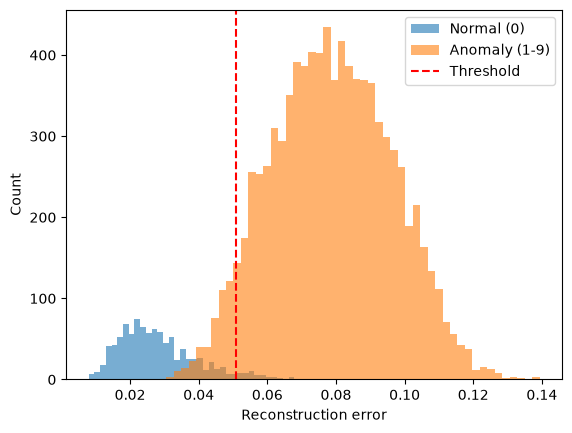

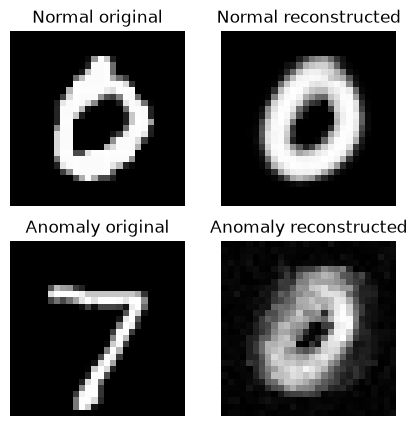

In [16]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix)

# Test set with both normal (0) and anomalous (1-9) digits
x_test_all = x_test.reshape(-1, 784)
y_true = (y_test != 0).astype(int)          # 1 = anomaly, 0 = normal

# Reconstruction error
recon = autoencoder.predict(x_test_all)
mse = np.mean(np.square(x_test_all - recon), axis=1)

# Threshold from NORMAL training data only
train_recon = autoencoder.predict(x_train)
train_mse = np.mean(np.square(x_train - train_recon), axis=1)
threshold = np.percentile(train_mse, 95)
print("Anomaly Threshold:", threshold)

# Detect anomalies
y_pred = (mse > threshold).astype(int)
print("Total Anomalies Detected:", np.sum(y_pred))

# Evaluation
print("Accuracy :", accuracy_score(y_true, y_pred))
print("Precision:", precision_score(y_true, y_pred))
print("Recall   :", recall_score(y_true, y_pred))
print("F1-score :", f1_score(y_true, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_true, y_pred))

# Reconstruction error distribution
plt.hist(mse[y_true == 0], bins=50, alpha=0.6, label='Normal (0)')
plt.hist(mse[y_true == 1], bins=50, alpha=0.6, label='Anomaly (1-9)')
plt.axvline(threshold, color='r', linestyle='--', label='Threshold')
plt.xlabel('Reconstruction error'); plt.ylabel('Count'); plt.legend()
plt.show()

# Original vs reconstructed (normal and anomaly)
fig, ax = plt.subplots(2, 2, figsize=(5, 5))
n = np.where(y_test == 0)[0][0]
a = np.where(y_test == 7)[0][0]
for row, (idx, title) in enumerate([(n, 'Normal'), (a, 'Anomaly')]):
    ax[row, 0].imshow(x_test_all[idx].reshape(28, 28), cmap='gray')
    ax[row, 0].set_title(f'{title} original'); ax[row, 0].axis('off')
    ax[row, 1].imshow(recon[idx].reshape(28, 28), cmap='gray')
    ax[row, 1].set_title(f'{title} reconstructed'); ax[row, 1].axis('off')
plt.show()

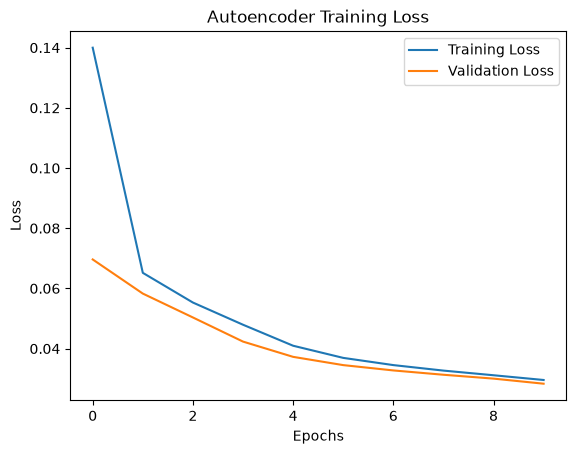

In [17]:
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('Autoencoder Training Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

Normal training data: (5923, 784)


Model: "sequential_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_9 (Sequential)       │ (None, 32)             │       110,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_10 (Sequential)      │ (None, 784)            │       111,568 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 222,384 (868.69 KB)

 Trainable params: 222,384 (868.69 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.1393 - mae: 0.3007 - val_loss: 0.0689 - val_mae: 0.1325
Epoch 2/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0652 - mae: 0.1316 - val_loss: 0.0594 - val_mae: 0.1278
Epoch 3/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0552 - mae: 0.1194 - val_loss: 0.0503 - val_mae: 0.1124
Epoch 4/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0465 - mae: 0.1050 - val_loss: 0.0434 - val_mae: 0.0979
Epoch 5/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0417 - mae: 0.0970 - val_loss: 0.0395 - val_mae: 0.0954
Epoch 6/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0380 - mae: 0.0917 - val_loss: 0.0364 - val_mae: 0.0889
Epoch 7/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0352 - mae: 0.0868 - val_loss: 0.0339 - val_mae: 0.0841
Epoch 8/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0330 - mae: 0.0828 - val_loss: 0.0320 - val_mae: 0.0811
Epoch 9/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0311 - mae: 

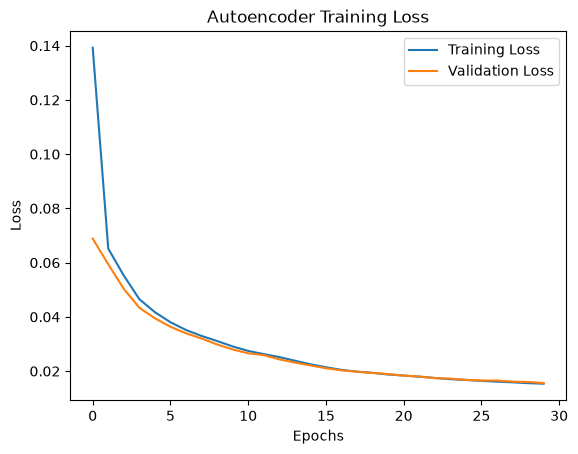

186/186 ━━━━━━━━━━━━━━━━━━━━ 0s 415us/step
Threshold: 0.028226309
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 313us/step
Anomalies detected: 8980
Accuracy : 0.985
Precision: 0.9938752783964365
Recall   : 0.9894678492239468
F1-score : 0.9916666666666667
Confusion Matrix:
 [[ 925   55]
 [  95 8925]]


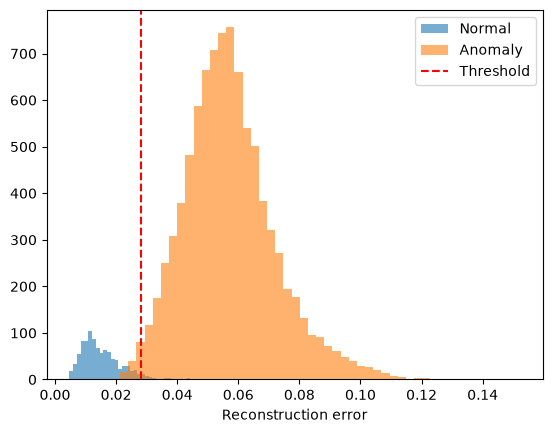

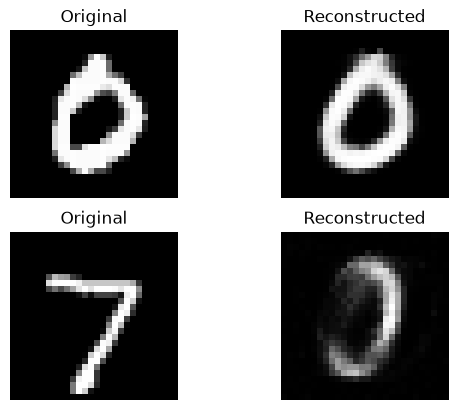

In [18]:
# a. Import required libraries
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# b. Access the dataset (MNIST)
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

# Normalize and flatten
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0
x_train = x_train.reshape(-1, 784)
x_test = x_test.reshape(-1, 784)

# Normal data = digit 0 (train only on normal)
x_train_normal = x_train[y_train == 0]
x_test_normal = x_test[y_test == 0]
print("Normal training data:", x_train_normal.shape)

# c. Encoder: input -> latent representation
encoder = keras.Sequential([
    layers.Input(shape=(784,)),
    layers.Dense(128, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(32, activation='relu')        # latent space
])

# d. Decoder: latent representation -> original input
decoder = keras.Sequential([
    layers.Input(shape=(32,)),
    layers.Dense(64, activation='relu'),
    layers.Dense(128, activation='relu'),
    layers.Dense(784, activation='sigmoid')
])

autoencoder = keras.Sequential([encoder, decoder])
autoencoder.summary()

# e. Compile with optimizer, loss and metrics
autoencoder.compile(optimizer='adam', loss='mse', metrics=['mae'])

# Train (input = target)
history = autoencoder.fit(x_train_normal, x_train_normal,
                          epochs=30, batch_size=256,
                          validation_data=(x_test_normal, x_test_normal))

# Evaluate on normal test data
loss, mae = autoencoder.evaluate(x_test_normal, x_test_normal)
print("Test Loss:", loss, " Test MAE:", mae)

# Training loss plot
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epochs'); plt.ylabel('Loss'); plt.legend()
plt.title('Autoencoder Training Loss')
plt.show()

# ---------- Anomaly Detection ----------
# Threshold from normal training data
train_recon = autoencoder.predict(x_train_normal)
train_mse = np.mean(np.square(x_train_normal - train_recon), axis=1)
threshold = np.percentile(train_mse, 95)
print("Threshold:", threshold)

# Reconstruction error on full test set (normal + anomaly)
recon = autoencoder.predict(x_test)
mse = np.mean(np.square(x_test - recon), axis=1)

y_true = (y_test != 0).astype(int)        # 1 = anomaly
y_pred = (mse > threshold).astype(int)    # error > threshold -> anomaly

print("Anomalies detected:", np.sum(y_pred))
print("Accuracy :", accuracy_score(y_true, y_pred))
print("Precision:", precision_score(y_true, y_pred))
print("Recall   :", recall_score(y_true, y_pred))
print("F1-score :", f1_score(y_true, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_true, y_pred))

# Error distribution
plt.hist(mse[y_true == 0], bins=50, alpha=0.6, label='Normal')
plt.hist(mse[y_true == 1], bins=50, alpha=0.6, label='Anomaly')
plt.axvline(threshold, color='r', linestyle='--', label='Threshold')
plt.xlabel('Reconstruction error'); plt.legend()
plt.show()

# Original vs reconstructed images
idx = [np.where(y_test == 0)[0][0], np.where(y_test == 7)[0][0]]
for i, k in enumerate(idx):
    plt.subplot(2, 2, 2*i + 1)
    plt.imshow(x_test[k].reshape(28, 28), cmap='gray'); plt.title('Original'); plt.axis('off')
    plt.subplot(2, 2, 2*i + 2)
    plt.imshow(recon[k].reshape(28, 28), cmap='gray'); plt.title('Reconstructed'); plt.axis('off')
plt.show()

In [1]:

import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# A. Import Required Libraries
print("TensorFlow Version:", tf.__version__)

# B. Upload / Access Dataset
# Generate normal data
np.random.seed(42)

normal_data = np.random.normal(0, 1, (1000, 10))

# Split training and testing data
X_train = normal_data[:800]
X_test = normal_data[800:]

# Add anomalous data
anomalies = np.random.normal(5, 1, (50, 10))

X_test = np.concatenate([X_test, anomalies])

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

# C. Encoder - Convert input into latent representation
input_dim = X_train.shape[1]

encoder_input = keras.Input(shape=(input_dim,))

encoded = layers.Dense(6, activation='relu')(encoder_input)
encoded = layers.Dense(3, activation='relu')(encoded)

# D. Decoder - Reconstruct original input
decoded = layers.Dense(6, activation='relu')(encoded)
decoded = layers.Dense(input_dim, activation='linear')(decoded)

# Build Autoencoder Model
autoencoder = keras.Model(encoder_input, decoded)

# E. Compile the Model
autoencoder.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

# Train the Model
autoencoder.fit(
    X_train, X_train,
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

# Detect Anomalies
reconstructed = autoencoder.predict(X_test, verbose=0)

# Calculate Reconstruction Error
errors = np.mean(np.square(X_test - reconstructed), axis=1)

# Set Threshold
threshold = np.percentile(errors[:200], 95)

# Classify Normal and Anomalous Data
predictions = errors > threshold

print("\nThreshold:", threshold)
print("\nAnomaly Detection Results:")

print("Normal Samples:", np.sum(predictions == False))
print("Anomalous Samples:", np.sum(predictions == True))

print("\nFirst 10 Predictions:")
for i in range(10):
    print("Sample", i+1,
          "Anomaly" if predictions[i] else "Normal")


TensorFlow Version: 2.21.0
Training Data Shape: (800, 10)
Testing Data Shape: (250, 10)
Epoch 1/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 1.0213 - mae: 0.8048 - val_loss: 1.1035 - val_mae: 0.8420
Epoch 2/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 865us/step - loss: 0.9933 - mae: 0.7938 - val_loss: 1.0836 - val_mae: 0.8341
Epoch 3/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 823us/step - loss: 0.9767 - mae: 0.7873 - val_loss: 1.0715 - val_mae: 0.8295
Epoch 4/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 937us/step - loss: 0.9643 - mae: 0.7824 - val_loss: 1.0629 - val_mae: 0.8261
Epoch 5/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 938us/step - loss: 0.9536 - mae: 0.7780 - val_loss: 1.0553 - val_mae: 0.8232
Epoch 6/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 925us/step - loss: 0.9433 - mae: 0.7739 - val_loss: 1.0473 - val_mae: 0.8201
Epoch 7/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 878us/step - loss: 0.9328 - mae: 0.7696 - val_loss: 1.0389 - val_mae: 0.8167
Epoch 8/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 903us/step - loss: 0.9218 - mae: 0.7652 - val_l